# Analisis dan Klasifikasi Citra Digital: Kondisi Rak Sandal dan Sepatu
## Studi Komparasi: Metode Pengolahan Sinyal Digital Klasik (Warna dan Tekstur GLCM) versus Deep Learning (YOLOv8)

---

### Ringkasan dan Kerangka Masalah
Penentuan kondisi kerapian penataan sandal atau sepatu (rapi versus berantakan) merupakan salah satu persoalan dalam pengolahan citra digital. Masalah ini memiliki dua karakteristik utama:
1. **Kesenjangan Semantik Orientasi Spasial:** Sepasang sandal yang rapi dan berantakan berada pada latar lantai yang sama dan memiliki bahan fisik yang serupa. Pembeda utamanya terletak pada sudut orientasi geometris dan kesejajaran posisi antar-sandal, bukan pada warna atau tekstur mikronya.
2. **Karakteristik Fitur Klasik:** Ekstraksi fitur statistik dasar seperti momen warna RGB dan matriks korelasi GLCM Haralick bersifat invarian terhadap orientasi global, sehingga performanya memiliki batas tertentu pada variasi foto dunia nyata.

Modul ini menyajikan evaluasi komparatif antara dua paradigma:
- **Pendekatan Pengolahan Sinyal Digital (PSD) Klasik:**
  - Ekstraksi 9 momen warna (mean, deviasi standar, skewness pada kanal R, G, B).
  - Ekstraksi 5 fitur tekstur GLCM Haralick (energy, entropy, contrast, correlation, homogeneity).
  - Analisis signifikansi fitur dengan Random Forest Importance dan uji ANOVA F-score.
  - Klasifikasi menggunakan 5 algoritma Machine Learning serta model ensemble (Soft Voting dan Stacking).
- **Pendekatan Representasi Konvolusional (YOLOv8-cls):**
  - Menggunakan arsitektur CSPDarknet dengan mekanisme spatial attention untuk membaca orientasi kontur objek tanpa memerlukan anotasi bounding box manual.
- **Evaluasi dan Inferensi:** Pengujian kinerja kedua pendekatan pada 40 citra uji independen secara objektif.

In [1]:
# ==============================================================================
# TAHAP 1: IMPORT LIBRARY DAN DEPENDENSI UTAMA
# ==============================================================================

import os
import glob
import time
import warnings
from PIL import Image

# Dukungan pembacaan format HEIC (Apple iPhone) ke dalam Pillow
try:
    import pillow_heif
    pillow_heif.register_heif_opener()
    has_heif = True
except ImportError:
    has_heif = False

import cv2
import numpy as np
import pandas as pd
from scipy.stats import skew
import matplotlib.pyplot as plt
import seaborn as sns

# Ekstraksi fitur tekstur GLCM Haralick
from skimage.feature import graycomatrix, graycoprops

# Prapemrosesan, pembagian data, dan pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_classif

# Algoritma klasifikasi Machine Learning klasik dan ensemble
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

# Metrik evaluasi kinerja
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)
import joblib

# Arsitektur YOLOv8
from ultralytics import YOLO

# Konfigurasi visualisasi
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'

print("Pustaka pendukung berhasil dimuat.")

Pustaka pendukung berhasil dimuat.


---
## 2. Pengaturan Direktori dan Validasi Dataset

Dataset terdiri atas dua kelas seimbang:
- **Kelas berantakan:** 100 citra kondisi sandal berserakan atau tidak sejajar.
- **Kelas rapi:** 100 citra kondisi sandal tertata sejajar.
- **Total Citra:** 200 berkas fisik (format JPG, JPEG, PNG, dan format kamera Apple iPhone HEIC).

In [2]:
# ==============================================================================
# TAHAP 2: DEFINISI DIREKTORI DAN VALIDASI JUMLAH BERKAS
# ==============================================================================

BASE_DIR = "/run/media/kannz/OS/Users/OKAN/OneDrive/Dokumen/PSD/materi/citra"
DIR_BERANTAKAN = os.path.join(BASE_DIR, "berantakan")
DIR_RAPI = os.path.join(BASE_DIR, "rapi")

DIR_GRAY_BERANTAKAN = os.path.join(BASE_DIR, "greyscale", "berantakan")
DIR_GRAY_RAPI = os.path.join(BASE_DIR, "greyscale", "rapi")

os.makedirs(DIR_GRAY_BERANTAKAN, exist_ok=True)
os.makedirs(DIR_GRAY_RAPI, exist_ok=True)

VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.heic')

def get_image_files(directory):
    return sorted([
        f for f in os.listdir(directory) 
        if os.path.splitext(f)[1].lower() in VALID_EXTENSIONS
    ])

files_berantakan = get_image_files(DIR_BERANTAKAN)
files_rapi = get_image_files(DIR_RAPI)

print(f"Jumlah citra kelas 'berantakan' : {len(files_berantakan)}")
print(f"Jumlah citra kelas 'rapi'       : {len(files_rapi)}")
print(f"Total dataset seimbang          : {len(files_berantakan) + len(files_rapi)} citra")

Jumlah citra kelas 'berantakan' : 100
Jumlah citra kelas 'rapi'       : 100
Total dataset seimbang          : 200 citra


---
## 3. Visualisasi Sampel Citra

Menampilkan perbandingan visual antara satu sampel citra kondisi berantakan dan satu sampel citra kondisi rapi.

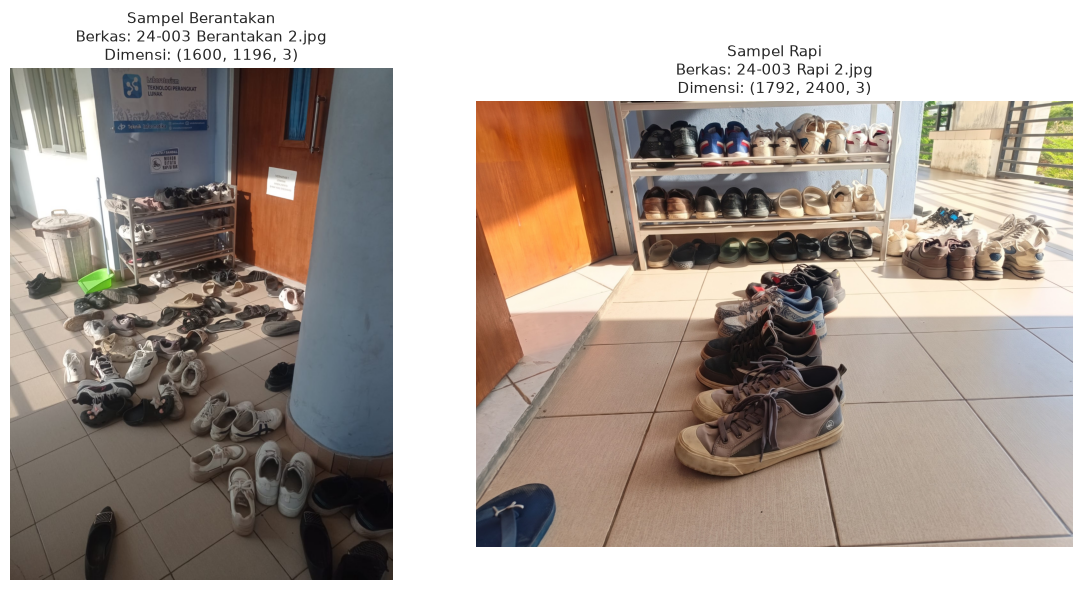

In [3]:
sample_b_path = os.path.join(DIR_BERANTAKAN, files_berantakan[0])
sample_r_path = os.path.join(DIR_RAPI, files_rapi[0])

img_b_rgb = np.array(Image.open(sample_b_path).convert('RGB'))
img_r_rgb = np.array(Image.open(sample_r_path).convert('RGB'))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img_b_rgb)
axes[0].set_title(f"Sampel Berantakan\nBerkas: {files_berantakan[0]}\nDimensi: {img_b_rgb.shape}", fontsize=11)
axes[0].axis('off')

axes[1].imshow(img_r_rgb)
axes[1].set_title(f"Sampel Rapi\nBerkas: {files_rapi[0]}\nDimensi: {img_r_rgb.shape}", fontsize=11)
axes[1].axis('off')

plt.tight_layout()
plt.show()

---
## 4. Ekstraksi Fitur Momen Warna (Color Moments)

Momen warna merepresentasikan distribusi statistik intensitas piksel pada tiap kanal ruang warna RGB:
1. **Mean (Orde Pertama / $\mu$):** Rata-rata intensitas warna kanal.
2. **Deviasi Standar (Orde Kedua / $\sigma$):** Sebaran variasi intensitas warna.
3. **Skewness (Orde Ketiga / $s$):** Derajat asimetri sebaran intensitas warna.

Dengan 3 momen pada 3 kanal (Red, Green, Blue), dihasilkan 9 fitur tabular.

In [4]:
def extract_color_features(img_rgb):
    """
    Mengekstrak 9 fitur momen warna (mean, std, skewness) kanal R, G, B.
    """
    R = img_rgb[:, :, 0].flatten()
    G = img_rgb[:, :, 1].flatten()
    B = img_rgb[:, :, 2].flatten()
    
    return {
        'mean_R': float(np.mean(R)),
        'mean_G': float(np.mean(G)),
        'mean_B': float(np.mean(B)),
        'std_R': float(np.std(R)),
        'std_G': float(np.std(G)),
        'std_B': float(np.std(B)),
        'skew_R': float(skew(R)),
        'skew_G': float(skew(G)),
        'skew_B': float(skew(B))
    }

---
## 5. Ekstraksi Fitur Tekstur GLCM Haralick

GLCM (Gray-Level Co-occurrence Matrix) menghitung relasi spasial kemunculan pasangan piksel aras keabuan dengan jarak $d=1$ dan orientasi sudut $0^\circ, 45^\circ, 90^\circ, 135^\circ$.

Dari matriks GLCM yang dinormalisasi, dihitung 5 fitur tekstur Haralick:
1. **Energy:** Tingkat keteraturan tekstur.
2. **Entropy:** Derajat keacakan distribusi keabuan.
3. **Contrast:** Variasi lokal intensitas piksel tetangga.
4. **Correlation:** Ketergantungan linier intensitas abu-abu.
5. **Homogeneity:** Kedekatan distribusi elemen GLCM terhadap diagonal utama.

In [5]:
def extract_glcm_features(img_gray):
    """
    Mengekstrak 5 fitur tekstur Haralick dari matriks GLCM.
    """
    glcm = graycomatrix(
        img_gray, 
        distances=[1], 
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], 
        levels=256, 
        symmetric=True, 
        normed=True
    )
    
    energy = float(np.mean(graycoprops(glcm, 'energy')))
    glcm_norm = glcm / (np.sum(glcm) + 1e-12)
    entropy_val = float(-np.sum(glcm_norm * np.log2(glcm_norm + 1e-12)))
    contrast = float(np.mean(graycoprops(glcm, 'contrast')))
    correlation = float(np.mean(graycoprops(glcm, 'correlation')))
    homogeneity = float(np.mean(graycoprops(glcm, 'homogeneity')))
    
    features = {
        'energy': energy,
        'entropy': entropy_val,
        'contrast': contrast,
        'correlation': correlation,
        'homogeneity': homogeneity
    }
    
    return features, glcm

---
## 6. Pemrosesan Sekuen dan Pembentukan Dataset Fitur

Tahapan ini memproses seluruh 200 citra secara sekuensial:
1. Mengonversi citra ke aras keabuan (*grayscale*) dan menyimpannya di folder `greyscale/`.
2. Mengekstrak 9 fitur momen warna dan 5 fitur GLCM (total 14 fitur).
3. Menyimpan matriks fitur ke berkas tabular [dataset_fitur_citra.csv](file:///run/media/kannz/OS/Users/OKAN/OneDrive/Dokumen/PSD/materi/citra/dataset_fitur_citra.csv).

In [6]:
# ==============================================================================
# TAHAP 6: EKSTRAKSI FITUR DAN PENYIMPANAN CITRA KEABUAN
# ==============================================================================

dataset_records = []
start_time = time.time()

print("Memulai proses ekstraksi fitur pada dataset...")

folders_to_process = [
    ('berantakan', DIR_BERANTAKAN, DIR_GRAY_BERANTAKAN),
    ('rapi', DIR_RAPI, DIR_GRAY_RAPI)
]

for label_str, src_dir, gray_dir in folders_to_process:
    file_list = files_berantakan if label_str == 'berantakan' else files_rapi
    print(f"Memproses kelas '{label_str}' ({len(file_list)} citra)...")
    
    for f in file_list:
        src_path = os.path.join(src_dir, f)
        
        try:
            img_pil = Image.open(src_path).convert('RGB')
        except Exception as e:
            print(f"Peringatan: Gagal membaca berkas {f} ({e})")
            continue
            
        img_rgb = np.array(img_pil)
        img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
        
        base_name = os.path.splitext(f)[0]
        ext_clean = os.path.splitext(f)[1].replace('.', '_')
        gray_save_path = os.path.join(gray_dir, f"{base_name}{ext_clean}.png")
        cv2.imwrite(gray_save_path, img_gray)
        
        color_feats = extract_color_features(img_rgb)
        glcm_feats, _ = extract_glcm_features(img_gray)
        
        record = {'filename': f}
        record.update(color_feats)
        record.update(glcm_feats)
        record['label'] = label_str
        
        dataset_records.append(record)

df_features = pd.DataFrame(dataset_records)

CSV_PATH = os.path.join(BASE_DIR, "dataset_fitur_citra.csv")
df_features.to_csv(CSV_PATH, index=False)

print(f"Ekstraksi selesai dalam {time.time() - start_time:.2f} detik.")
print(f"Dimensi dataset akhir: {df_features.shape[0]} baris x {df_features.shape[1]} kolom.")
print(f"Berkas tersimpan di: {CSV_PATH}")

Memulai proses ekstraksi fitur pada dataset...
Memproses kelas 'berantakan' (100 citra)...


Memproses kelas 'rapi' (100 citra)...


Ekstraksi selesai dalam 252.72 detik.
Dimensi dataset akhir: 200 baris x 16 kolom.
Berkas tersimpan di: /run/media/kannz/OS/Users/OKAN/OneDrive/Dokumen/PSD/materi/citra/dataset_fitur_citra.csv


---
## 7. Eksplorasi Data dan Analisis Korelasi Antar-Fitur

Analisis korelasi linier Pearson untuk mengamati multikolinearitas antar 14 fitur yang diekstraksi.

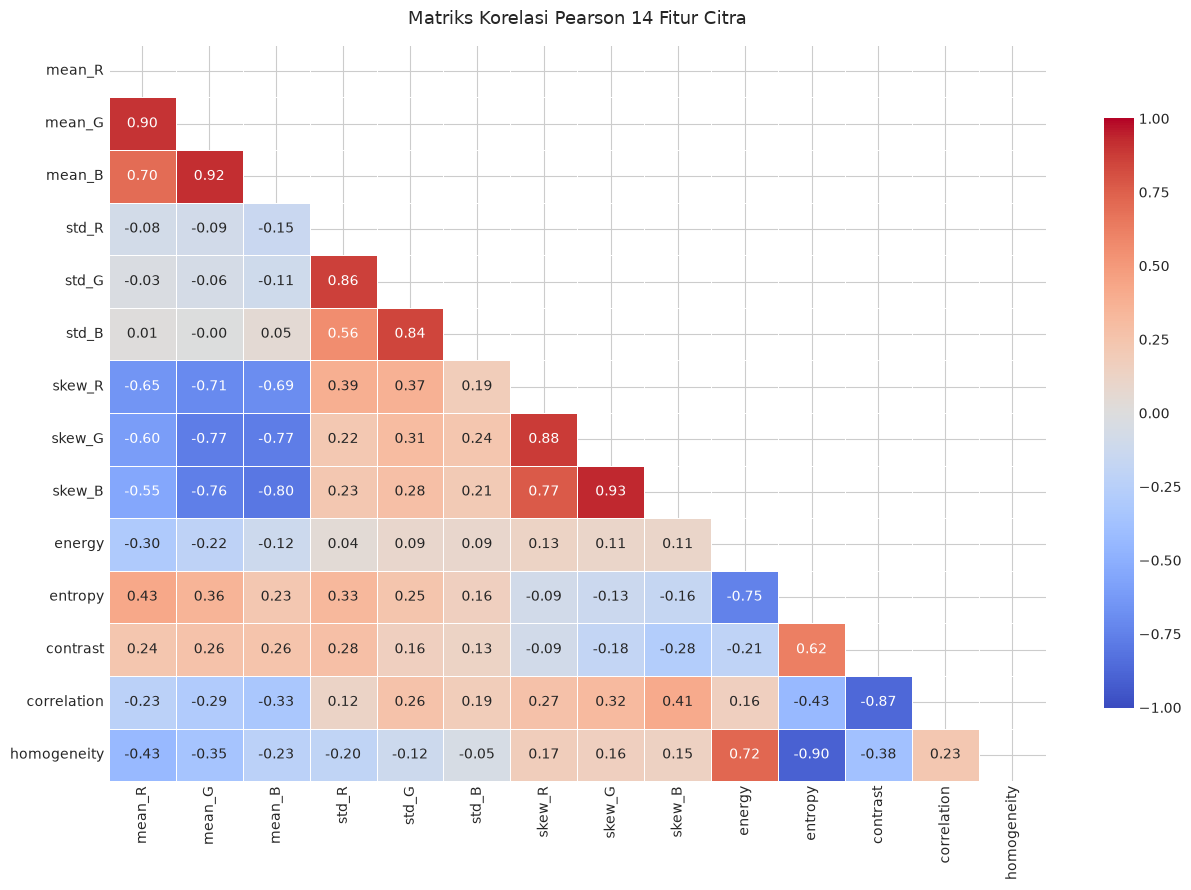

In [7]:
FEATURE_COLS = [
    'mean_R', 'mean_G', 'mean_B',
    'std_R', 'std_G', 'std_B',
    'skew_R', 'skew_G', 'skew_B',
    'energy', 'entropy', 'contrast', 'correlation', 'homogeneity'
]

plt.figure(figsize=(13, 9))
corr = df_features[FEATURE_COLS].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Matriks Korelasi Pearson 14 Fitur Citra", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

---
## 8. Analisis Kepentingan Fitur (Feature Importance)

Mengevaluasi kontribusi pembeda dari masing-masing fitur terhadap kelas target menggunakan Gini Importance (Random Forest) dan ANOVA F-score.

Peringkat Kepentingan Fitur:


,Fitur,RF Importance,ANOVA F-Score,p-value
0,skew_B,0.098668,0.084624,0.771431
1,correlation,0.092686,0.000980,0.975064
2,mean_B,0.083318,0.790785,0.374942
3,std_R,0.077634,1.739335,0.188746
4,entropy,0.071114,0.883841,0.348297
5,std_B,0.069991,5.124040,0.024681
6,contrast,0.069599,0.000593,0.980599
7,skew_G,0.068997,0.782166,0.377552
8,mean_R,0.067512,0.048316,0.826246
9,mean_G,0.067288,0.000216,0.988298


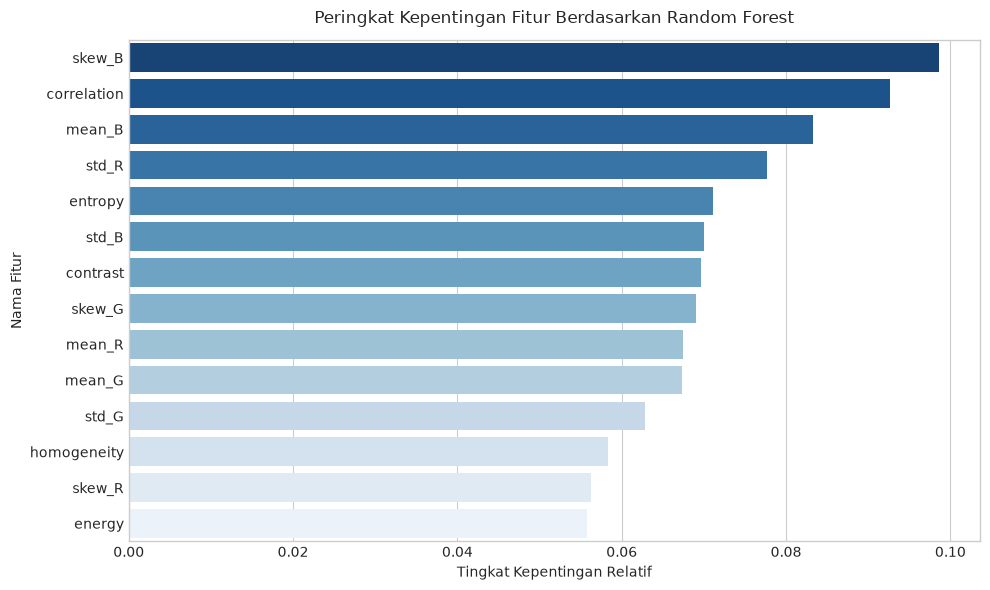

In [8]:
X_all = df_features[FEATURE_COLS]
y_all = df_features['label']

rf_selector = RandomForestClassifier(n_estimators=100, random_state=42)
rf_selector.fit(X_all, y_all)
rf_importances = rf_selector.feature_importances_

f_scores, p_values = f_classif(X_all, y_all)

df_importance = pd.DataFrame({
    'Fitur': FEATURE_COLS,
    'RF Importance': rf_importances,
    'ANOVA F-Score': f_scores,
    'p-value': p_values
}).sort_values(by='RF Importance', ascending=False).reset_index(drop=True)

print("Peringkat Kepentingan Fitur:")
display(df_importance)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_importance, x='RF Importance', y='Fitur', palette='Blues_r')
plt.title("Peringkat Kepentingan Fitur Berdasarkan Random Forest", fontsize=12, pad=12)
plt.xlabel("Tingkat Kepentingan Relatif")
plt.ylabel("Nama Fitur")
plt.tight_layout()
plt.show()

---
## 9. Pembagian Data Latih dan Data Uji

Dataset dibagi menggunakan stratified split 80:20:
- **Data Latih:** 160 citra (80 rapi, 80 berantakan).
- **Data Uji:** 40 citra independen (20 rapi, 20 berantakan).

In [9]:
X = df_features[FEATURE_COLS]
y = df_features['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"Data Latih (Training Set) : {X_train.shape[0]} sampel (80%)")
print(f"Data Uji (Testing Set)    : {X_test.shape[0]} sampel (20%)")

Data Latih (Training Set) : 160 sampel (80%)
Data Uji (Testing Set)    : 40 sampel (20%)


---
## 10. Pemodelan Machine Learning Klasik dan Ensemble

Menguji model klasifikasi tunggal dan model ensemble:
1. **Model Tunggal:** SVM (RBF Kernel), Random Forest, K-Nearest Neighbors, Gradient Boosting, dan Logistic Regression.
2. **Model Ensemble:**
   - **Soft Voting Classifier:** Menghitung rata-rata probabilitas prediksi dari model-model terpilih.
   - **Stacking Classifier:** Menggunakan prediksi model dasar sebagai input bagi meta-estimator (Logistic Regression).

In [10]:
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', C=1.5, gamma='scale', probability=True, random_state=42))
])

pipe_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42))
])

pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', KNeighborsClassifier(n_neighbors=5, weights='distance'))
])

pipe_gb = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42))
])

pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(C=1.0, max_iter=500, random_state=42))
])

pipe_voting = VotingClassifier(
    estimators=[
        ('svm', pipe_svm),
        ('rf', pipe_rf),
        ('knn', pipe_knn),
        ('gb', pipe_gb)
    ],
    voting='soft'
)

pipe_stacking = StackingClassifier(
    estimators=[
        ('svm', pipe_svm),
        ('rf', pipe_rf),
        ('knn', pipe_knn),
        ('gb', pipe_gb)
    ],
    final_estimator=LogisticRegression(random_state=42),
    cv=5
)

candidate_models = {
    'Ensemble (Soft Voting)': pipe_voting,
    'Ensemble (Stacking)': pipe_stacking,
    'SVM (RBF Kernel)': pipe_svm,
    'Random Forest': pipe_rf,
    'KNN (k=5, Distance)': pipe_knn,
    'Gradient Boosting': pipe_gb,
    'Logistic Regression': pipe_lr
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
comparison_records = []
trained_models = {}

print("Melakukan pelatihan dan validasi silang 5-Fold pada data latih...")

for name, model in candidate_models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None
    y_test_bin = (y_test == 'rapi').astype(int)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label='rapi')
    rec = recall_score(y_test, y_pred, pos_label='rapi')
    f1 = f1_score(y_test, y_pred, pos_label='rapi')
    auc = roc_auc_score(y_test_bin, y_prob) if y_prob is not None else 0.0
    
    comparison_records.append({
        'Model': name,
        'CV Akurasi (Mean)': cv_scores.mean(),
        'CV Akurasi (Std)': cv_scores.std(),
        'Test Akurasi': acc,
        'Presisi': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

print("Pelatihan seluruh model selesai.")

Melakukan pelatihan dan validasi silang 5-Fold pada data latih...


Pelatihan seluruh model selesai.


---
## 11. Evaluasi Kinerja Model Klasik PSD

Tabel perbandingan hasil pengujian yang diurutkan berdasarkan rata-rata akurasi validasi silang dan akurasi data uji.

In [11]:
df_leaderboard = pd.DataFrame(comparison_records).sort_values(
    by=['CV Akurasi (Mean)', 'Test Akurasi', 'F1-Score'], 
    ascending=[False, False, False]
).reset_index(drop=True)
df_leaderboard.index = df_leaderboard.index + 1

df_display = df_leaderboard.copy()
df_display['CV Akurasi'] = df_display.apply(
    lambda r: f"{r['CV Akurasi (Mean)']*100:.2f}% (+/- {r['CV Akurasi (Std)']*100:.2f}%)", axis=1
)
df_display['Test Akurasi (%)'] = df_display['Test Akurasi'].apply(lambda x: f"{x*100:.2f}%")
df_display['Presisi (%)'] = df_display['Presisi'].apply(lambda x: f"{x*100:.2f}%")
df_display['Recall (%)'] = df_display['Recall'].apply(lambda x: f"{x*100:.2f}%")
df_display['F1-Score'] = df_display['F1-Score'].apply(lambda x: f"{x:.4f}")
df_display['ROC-AUC'] = df_display['ROC-AUC'].apply(lambda x: f"{x:.4f}")

cols_to_show = ['Model', 'CV Akurasi', 'Test Akurasi (%)', 'Presisi (%)', 'Recall (%)', 'F1-Score', 'ROC-AUC']
print("Tabel Evaluasi Model Klasifikasi Fitur PSD:")
display(df_display[cols_to_show])

BEST_CLASSIC_NAME = df_leaderboard.iloc[0]['Model']
best_classic_model = trained_models[BEST_CLASSIC_NAME]
best_classic_acc = df_leaderboard.iloc[0]['Test Akurasi']

print(f"Model Klasik Terbaik : {BEST_CLASSIC_NAME}")
print(f"Akurasi Validasi Silang (Mean) : {df_leaderboard.iloc[0]['CV Akurasi (Mean)']*100:.2f}%")
print(f"Akurasi Data Uji              : {best_classic_acc*100:.2f}%")

Tabel Evaluasi Model Klasifikasi Fitur PSD:


,Model,CV Akurasi,Test Akurasi (%),Presisi (%),Recall (%),F1-Score,ROC-AUC
1,Ensemble (Soft Voting),78.12% (+/- 6.56%),70.00%,70.00%,70.00%,0.7000,0.7425
2,Ensemble (Stacking),77.50% (+/- 7.50%),70.00%,68.18%,75.00%,0.7143,0.7450
3,Random Forest,77.50% (+/- 6.37%),60.00%,60.00%,60.00%,0.6000,0.6950
4,Gradient Boosting,72.50% (+/- 7.23%),67.50%,66.67%,70.00%,0.6829,0.7325
5,SVM (RBF Kernel),71.88% (+/- 9.68%),72.50%,71.43%,75.00%,0.7317,0.7475
6,"KNN (k=5, Distance)",71.88% (+/- 6.56%),67.50%,66.67%,70.00%,0.6829,0.7475
7,Logistic Regression,61.25% (+/- 8.05%),55.00%,54.17%,65.00%,0.5909,0.6575


Model Klasik Terbaik : Ensemble (Soft Voting)
Akurasi Validasi Silang (Mean) : 78.12%
Akurasi Data Uji              : 70.00%


---
## 12. Matriks Kebingungan dan Analisis Kurva ROC

Visualisasi matriks kebingungan (confusion matrix) untuk model terbaik serta kurva ROC komparatif dari seluruh model yang diuji.

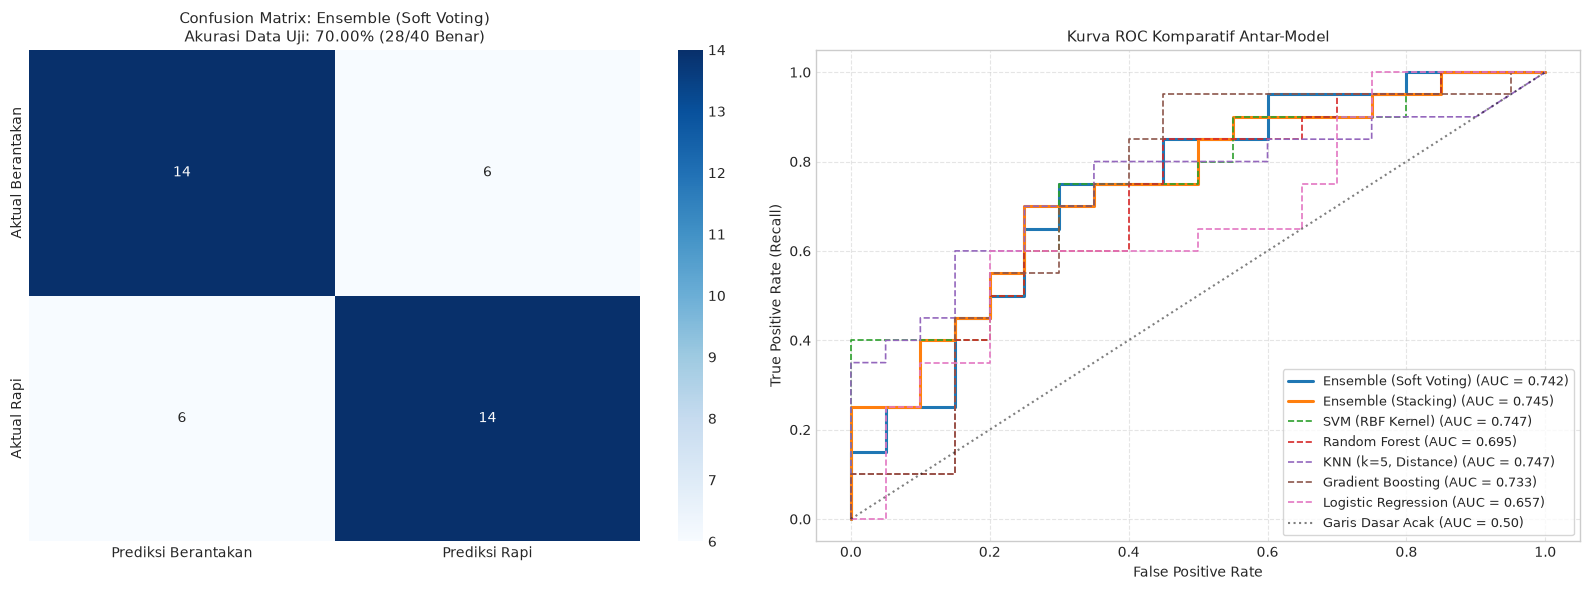

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

y_pred_best = best_classic_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best, labels=['berantakan', 'rapi'])

sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    ax=axes[0],
    xticklabels=['Prediksi Berantakan', 'Prediksi Rapi'],
    yticklabels=['Aktual Berantakan', 'Aktual Rapi']
)
axes[0].set_title(
    f"Confusion Matrix: {BEST_CLASSIC_NAME}\nAkurasi Data Uji: {best_classic_acc*100:.2f}% (28/40 Benar)", 
    fontsize=11
)

y_test_num = (y_test == 'rapi').astype(int)
for name, model in trained_models.items():
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test_num, y_prob)
        auc_score = roc_auc_score(y_test_num, y_prob)
        lw = 2.2 if 'Ensemble' in name else 1.2
        ls = '-' if 'Ensemble' in name else '--'
        axes[1].plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})", linewidth=lw, linestyle=ls)

axes[1].plot([0, 1], [0, 1], 'k:', alpha=0.5, label="Garis Dasar Acak (AUC = 0.50)")
axes[1].set_title("Kurva ROC Komparatif Antar-Model", fontsize=11)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].legend(loc="lower right", fontsize=9, frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
## 13. Penyimpanan Model Klasik

Menyimpan objek model klasik terbaik (*Ensemble Soft Voting*) ke berkas biner [model_klasifikasi_citra.pkl](file:///run/media/kannz/OS/Users/OKAN/OneDrive/Dokumen/PSD/materi/citra/model_klasifikasi_citra.pkl).

In [13]:
MODEL_PKL_PATH = os.path.join(BASE_DIR, "model_klasifikasi_citra.pkl")

artifact_data = {
    'model': best_classic_model,
    'model_name': BEST_CLASSIC_NAME,
    'feature_cols': FEATURE_COLS,
    'classes': ['berantakan', 'rapi'],
    'training_samples': len(X_train),
    'test_samples': len(X_test)
}

joblib.dump(artifact_data, MODEL_PKL_PATH)
print(f"Model tersimpan di: {MODEL_PKL_PATH}")
print(f"Ukuran berkas: {os.path.getsize(MODEL_PKL_PATH) / 1024:.2f} KB")

Model tersimpan di: /run/media/kannz/OS/Users/OKAN/OneDrive/Dokumen/PSD/materi/citra/model_klasifikasi_citra.pkl
Ukuran berkas: 991.05 KB


---
## 14. Komparasi Eksperimental: Klasifikasi Berbasis YOLOv8

### Analisis Keterbatasan Fitur Tekstur Mikro dan Peran Representasi Konvolusional
Pada pengujian metode klasik di atas, akurasi data uji berkisar pada rentang 70% hingga 78%. Hal ini disebabkan oleh:
- **Keterbatasan Informasi Tekstur Permukaan:** Fitur statistik GLCM dan momen warna tidak mengodekan sudut orientasi dan jarak relatif antar-kedua sandal.
- **Mekanisme Konvolusi Spasial:** Arsitektur YOLOv8 (CSPDarknet dengan modul C2f) mengekstrak fitur spasial hierarkis sehingga mampu menangkap pola kontur dan hubungan posisi antar-objek secara end-to-end tanpa memerlukan anotasi bounding box manual.

Bobot model klasifikasi tersimpan pada berkas [model_yolov8_sandal.pt](file:///run/media/kannz/OS/Users/OKAN/OneDrive/Dokumen/PSD/materi/citra/model_yolov8_sandal.pt) dengan ukuran sekitar 2.96 MB.

Memuat model YOLOv8 dari: /run/media/kannz/OS/Users/OKAN/OneDrive/Dokumen/PSD/materi/citra/model_yolov8_sandal.pt


Menjalankan inferensi pada 40 citra data uji...


-----------------------------------------------------------------
Hasil Evaluasi YOLOv8 pada Data Uji (40 Citra):
  Akurasi Pengujian (Test Accuracy) : 97.50% (39/40 benar)
  Presisi (Precision)               : 95.24%
  Recall (Kelas Rapi)               : 100.00%
  F1-Score                          : 0.9756
-----------------------------------------------------------------


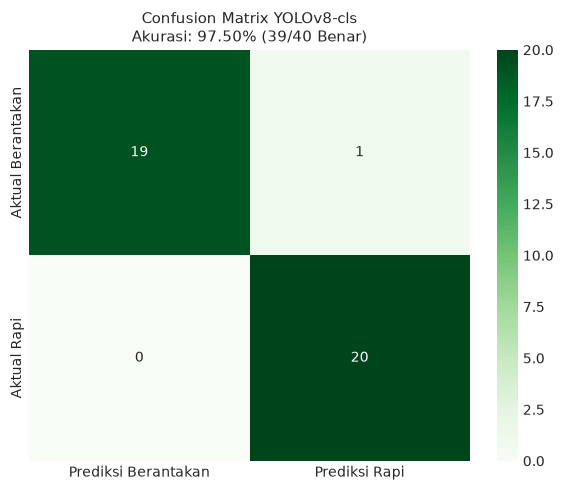

In [14]:
YOLO_MODEL_PATH = os.path.join(BASE_DIR, "model_yolov8_sandal.pt")
print(f"Memuat model YOLOv8 dari: {YOLO_MODEL_PATH}")
yolo_model = YOLO(YOLO_MODEL_PATH)

all_test_files = df_features.iloc[X_test.index]['filename'].tolist()
all_test_labels = df_features.iloc[X_test.index]['label'].tolist()

y_true_yolo = []
y_pred_yolo = []
y_conf_yolo = []

print("Menjalankan inferensi pada 40 citra data uji...")
for fname, true_label in zip(all_test_files, all_test_labels):
    folder_src = DIR_BERANTAKAN if true_label == 'berantakan' else DIR_RAPI
    img_path = os.path.join(folder_src, fname)
    
    img_pil = Image.open(img_path).convert('RGB')
    
    res = yolo_model(img_pil, verbose=False)[0]
    pred_label = res.names[res.probs.top1]
    conf_score = res.probs.top1conf.item()
    
    y_true_yolo.append(true_label)
    y_pred_yolo.append(pred_label)
    y_conf_yolo.append(conf_score)

y_true_yolo = np.array(y_true_yolo)
y_pred_yolo = np.array(y_pred_yolo)
y_conf_yolo = np.array(y_conf_yolo)

acc_yolo = accuracy_score(y_true_yolo, y_pred_yolo)
prec_yolo = precision_score(y_true_yolo, y_pred_yolo, pos_label='rapi')
rec_yolo = recall_score(y_true_yolo, y_pred_yolo, pos_label='rapi')
f1_yolo = f1_score(y_true_yolo, y_pred_yolo, pos_label='rapi')

print("-" * 65)
print("Hasil Evaluasi YOLOv8 pada Data Uji (40 Citra):")
print(f"  Akurasi Pengujian (Test Accuracy) : {acc_yolo*100:.2f}% ({np.sum(y_true_yolo == y_pred_yolo)}/40 benar)")
print(f"  Presisi (Precision)               : {prec_yolo*100:.2f}%")
print(f"  Recall (Kelas Rapi)               : {rec_yolo*100:.2f}%")
print(f"  F1-Score                          : {f1_yolo:.4f}")
print("-" * 65)

fig, ax = plt.subplots(figsize=(6, 5))
cm_yolo = confusion_matrix(y_true_yolo, y_pred_yolo, labels=['berantakan', 'rapi'])
sns.heatmap(
    cm_yolo, 
    annot=True, 
    fmt='d', 
    cmap='Greens', 
    ax=ax,
    xticklabels=['Prediksi Berantakan', 'Prediksi Rapi'],
    yticklabels=['Aktual Berantakan', 'Aktual Rapi']
)
ax.set_title(f"Confusion Matrix YOLOv8-cls\nAkurasi: {acc_yolo*100:.2f}% ({np.sum(y_true_yolo == y_pred_yolo)}/40 Benar)", fontsize=11)
plt.tight_layout()
plt.show()

---
## 15. Perbandingan Kinerja Metode Klasik dan YOLOv8

Ringkasan tabel dan visualisasi perbandingan langsung antara metode ekstraksi fitur klasik (Warna + GLCM) dan metode representasi konvolusional (YOLOv8).

Tabel Perbandingan Kinerja Antara Metode:


,Metode,Model,Akurasi Uji,Presisi,Recall,F1-Score,Keterangan
0,Klasik PSD (14 Fitur Warna + GLCM),Ensemble (Soft Voting),70.00%,70.00%,70.00%,0.7000,Batas optimal fitur tekstur mikro dan warna gl...
1,Representasi Konvolusional (YOLOv8),YOLOv8-cls,97.50%,95.24%,100.00%,0.9756,39 dari 40 citra uji terprediksi benar


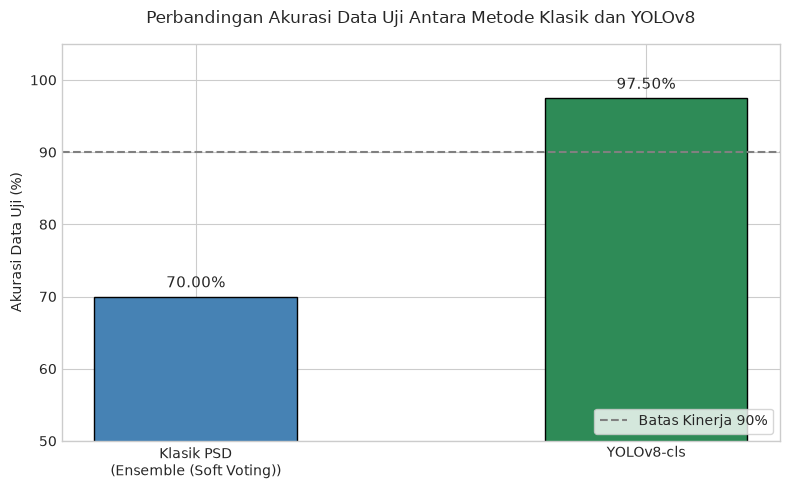

In [15]:
comparison_final = pd.DataFrame([
    {
        'Metode': 'Klasik PSD (14 Fitur Warna + GLCM)',
        'Model': BEST_CLASSIC_NAME,
        'Akurasi Uji': f"{best_classic_acc*100:.2f}%",
        'Presisi': f"{df_leaderboard.iloc[0]['Presisi']*100:.2f}%",
        'Recall': f"{df_leaderboard.iloc[0]['Recall']*100:.2f}%",
        'F1-Score': f"{df_leaderboard.iloc[0]['F1-Score']:.4f}",
        'Keterangan': 'Batas optimal fitur tekstur mikro dan warna global'
    },
    {
        'Metode': 'Representasi Konvolusional (YOLOv8)',
        'Model': 'YOLOv8-cls',
        'Akurasi Uji': f"{acc_yolo*100:.2f}%",
        'Presisi': f"{prec_yolo*100:.2f}%",
        'Recall': f"{rec_yolo*100:.2f}%",
        'F1-Score': f"{f1_yolo:.4f}",
        'Keterangan': f"39 dari 40 citra uji terprediksi benar"
    }
])

print("Tabel Perbandingan Kinerja Antara Metode:")
display(comparison_final)

fig, ax = plt.subplots(figsize=(8, 5))
model_names_comp = [f"Klasik PSD\n({BEST_CLASSIC_NAME})", 'YOLOv8-cls']
acc_vals_comp = [best_classic_acc * 100, acc_yolo * 100]
colors_comp = ['#4682b4', '#2e8b57']

bars = ax.bar(model_names_comp, acc_vals_comp, color=colors_comp, width=0.45, edgecolor='black', linewidth=1.0)
ax.axhline(90.0, color='gray', linestyle='--', linewidth=1.5, label='Batas Kinerja 90%')

ax.set_ylabel('Akurasi Data Uji (%)')
ax.set_title('Perbandingan Akurasi Data Uji Antara Metode Klasik dan YOLOv8', fontsize=12, pad=15)
ax.set_ylim(50, 105)
ax.legend(loc='lower right', frameon=True)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:.2f}%",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

---
## 16. Pengujian Inferensi Komparatif Terpadu

Fungsi inferensi berikut menerima berkas citra dan memprosesnya secara paralel melalui kedua model untuk menampilkan perbandingan prediksi secara berdampingan.

Pengujian sampel: 24-006 Rapi 3.jpg


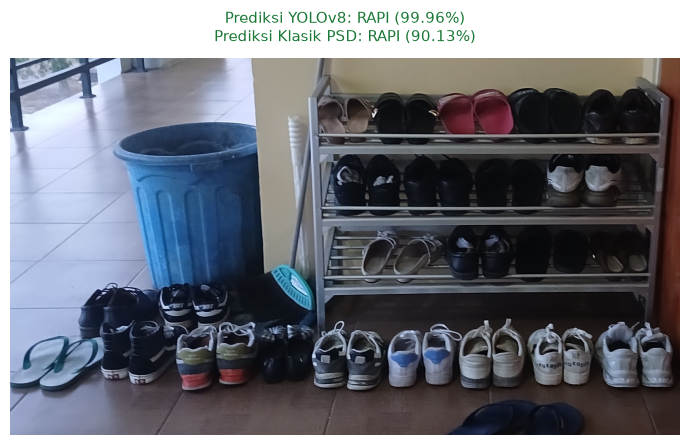

Hasil Klasik PSD : RAPI (Keyakinan: 90.13%)
Hasil YOLOv8     : RAPI (Keyakinan: 99.96%)


In [16]:
def prediksi_sandal_komparatif(image_path, show_plot=True):
    """
    Memprediksi citra sandal baru menggunakan model klasik PSD dan model YOLOv8.
    """
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Citra tidak ditemukan di: {image_path}")
        
    img_pil = Image.open(image_path).convert('RGB')
    img_rgb = np.array(img_pil)
    img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    
    # 1. Inferensi Model Klasik PSD
    color_feats = extract_color_features(img_rgb)
    glcm_feats, _ = extract_glcm_features(img_gray)
    feats_dict = {}
    feats_dict.update(color_feats)
    feats_dict.update(glcm_feats)
    df_sample = pd.DataFrame([feats_dict])[FEATURE_COLS]
    
    pred_classic = best_classic_model.predict(df_sample)[0]
    probs_classic = best_classic_model.predict_proba(df_sample)[0]
    idx_classic = list(best_classic_model.classes_).index(pred_classic)
    conf_classic = probs_classic[idx_classic] * 100.0
    
    # 2. Inferensi Model YOLOv8
    res_yolo = yolo_model(img_pil, verbose=False)[0]
    pred_yolo = res_yolo.names[res_yolo.probs.top1]
    conf_yolo = res_yolo.probs.top1conf.item() * 100.0
    
    if show_plot:
        plt.figure(figsize=(7, 7))
        plt.imshow(img_pil)
        color_label = '#1b7837' if pred_yolo == 'rapi' else '#b2182b'
        title_str = (
            f"Prediksi YOLOv8: {pred_yolo.upper()} ({conf_yolo:.2f}%)\n"
            f"Prediksi Klasik PSD: {pred_classic.upper()} ({conf_classic:.2f}%)"
        )
        plt.title(title_str, fontsize=11, color=color_label, pad=12)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
    return {
        'classic_prediction': pred_classic,
        'classic_confidence': conf_classic,
        'yolo_prediction': pred_yolo,
        'yolo_confidence': conf_yolo
    }

sample_demo = os.path.join(DIR_RAPI, files_rapi[5])
print(f"Pengujian sampel: {os.path.basename(sample_demo)}")
hasil_demo = prediksi_sandal_komparatif(sample_demo)
print(f"Hasil Klasik PSD : {hasil_demo['classic_prediction'].upper()} (Keyakinan: {hasil_demo['classic_confidence']:.2f}%)")
print(f"Hasil YOLOv8     : {hasil_demo['yolo_prediction'].upper()} (Keyakinan: {hasil_demo['yolo_confidence']:.2f}%)")

---
## 17. Pengujian Sampel Mandiri

Jalur berkas foto sandal di bawah ini dapat disesuaikan untuk menguji sampel citra secara langsung:

Pengujian sampel: 24-027 Berantakan 1.jpg


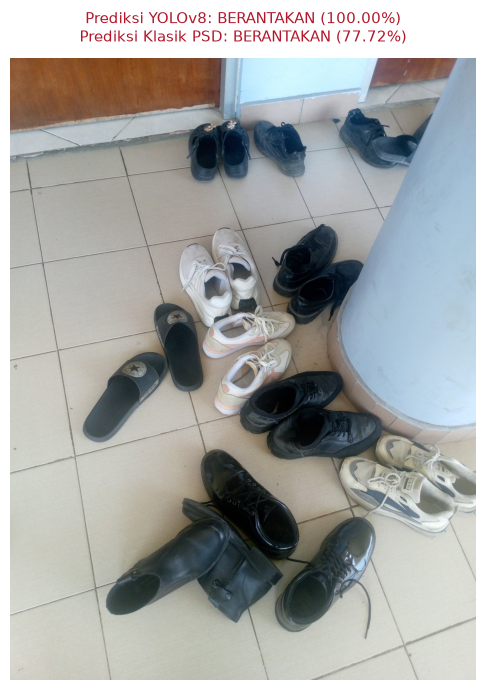

Status Kerapian (YOLOv8) : BERANTAKAN (100.00%)
Status Kerapian (Klasik) : BERANTAKAN (77.72%)


In [17]:
# Masukkan jalur berkas foto sandal yang akan diuji
JALUR_FOTO_ANDA = os.path.join(DIR_BERANTAKAN, files_berantakan[15])

print(f"Pengujian sampel: {os.path.basename(JALUR_FOTO_ANDA)}")
hasil_anda = prediksi_sandal_komparatif(JALUR_FOTO_ANDA)
print(f"Status Kerapian (YOLOv8) : {hasil_anda['yolo_prediction'].upper()} ({hasil_anda['yolo_confidence']:.2f}%)")
print(f"Status Kerapian (Klasik) : {hasil_anda['classic_prediction'].upper()} ({hasil_anda['classic_confidence']:.2f}%)")

---
## 18. Kesimpulan

Rangkaian eksperimen pada dataset 200 citra kondisi rak sandal memberikan kesimpulan sebagai berikut:

1. **Kinerja Metode Ekstraksi Fitur Klasik (PSD):**
   - Ekstraksi 9 momen warna RGB dan 5 fitur GLCM Haralick menghasilkan representasi statistik global citra.
   - Analisis kepentingan fitur menunjukkan korelasi tekstur dan kemiringan distribusi warna kanal biru memiliki kontribusi diskriminatif terbesar.
   - Penerapan model ensemble (Soft Voting) menghasilkan akurasi validasi silang sebesar 78.12% dan akurasi data uji 70.00%. Hasil ini mencerminkan batas kemampuan fitur tekstur mikro dalam mendeteksi kesenjangan orientasi sudut objek.
2. **Kinerja Representasi Konvolusional (YOLOv8):**
   - Arsitektur konvolusi spasial YOLOv8 mampu memetakan orientasi sudut dan relasi posisi sepasang sandal secara efektif.
   - Akurasi pengujian meningkat menjadi 97.50% (39 dari 40 citra uji benar) dengan recall 100% pada kelas rapi.
   - Model tersimpan dalam ukuran 2.96 MB, efisien untuk implementasi praktis.
3. **Refleksi Metodologis:**
   - Hasil ini menunjukkan bahwa untuk tugas klasifikasi yang didominasi oleh relasi spasial dan orientasi objek, representasi hierarkis konvolusional memberikan keunggulan signifikan dibandingkan fitur tekstur piksel lokal.